# Chapter 6 · Vector Data & Deep NLP: Learned Neural Embeddings & Hybrid Search (`vktorch` + `vkvec`)

In Chapter 5, `vkvec.TfidfVectorizer` + GPU `Ridge` scored **`97.30%`** on our **2,225 full-length BBC News articles** — **but** hit two classic walls:
1. **Giant Sparse Vectors:** Every article took `2,000` numbers (mostly zeros).
2. **The Synonym Wall (`0.000`):** Two phrases with the exact same meaning (`"football striker match coach goal"` vs. `"rugby olympic tournament champion"`) scored **`0.000`** because they shared zero exact words!

### How Modern AI Solves This: Learned 64-D Neural Embeddings + Hybrid Search
In this chapter we use the **exact same 1,780 / 445 BBC News split** to:
1. Train a **`vktorch` Neural Text Encoder** (`3,000 → 128 → 64`-D bottleneck → `5` classes) using fused SPIR-V `LayerNorm`, `GELU`, `CrossEntropy`, and `AdamW`.
2. Compress every full-length article into a **64-D dense meaning vector (`31×` smaller!)** and beat every Classical NLP baseline.
3. **Shatter the Synonym Wall** on zero-word-overlap synonym pairs.
4. Visualize the learned 64-D meaning space with **`vkvis.UMAP`**.
5. Build a production **`vkvec.HybridIndex`** fusing **Okapi `BM25` keyword search** + **64-D GPU neural search** via **Reciprocal Rank Fusion (`RRF`)**, and persist both model & index to disk!

In [1]:
import sys, time
from pathlib import Path
from IPython.display import display

for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
    if (p / "vknumpy").is_dir() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

import vknumpy as vnp
import vkpandas as vpd
import vklearn as vkl
import vktorch as vt
import vktorch.nn as nn
import vktorch.functional as F
from vktorch.data import DataLoader, TensorDataset
import vkvis
import vkvec

print(f"Vulkan GPU ready: {vnp.device_info()['name']}")

df, CLASS_NAMES = vkvec.load_bbc_news()
PALETTE = ["#36f9f6", "#ff7edb", "#fede5d", "#72f1b8", "#ff9e64"]
cat2id = {c.lower(): i for i, c in enumerate(CLASS_NAMES)}
all_texts  = df["text"].to_list()
all_labels = vnp.array([cat2id[c] for c in df["category"].to_list()])
texts_tr, texts_te, y_tr, y_te = vkl.train_test_split(all_texts, all_labels, test_size=0.2, random_state=42)

# 3,000-word TF-IDF GPU input layer for our Neural Text Encoder
vec = vkvec.TfidfVectorizer(max_features=3000, use_idf=True, sublinear_tf=True, l2_normalize=True)
X_tr, X_te = vec.fit_transform(texts_tr), vec.transform(texts_te)
print(f"Loaded {len(texts_tr):,} train / {len(texts_te):,} test full-length BBC articles -> GPU input shape {X_tr.shape}")


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


Vulkan GPU ready: AMD Custom GPU 0405 (RADV VANGOGH)


Loaded 1,780 train / 445 test full-length BBC articles -> GPU input shape (1780, 3000)


---
### Step 1 · Designing & Training the `vktorch` Neural Text Encoder (Bottleneck `Embedding`)

Look at the architecture below: `3,000 → 128 → 64 → 5`. Why squeeze through a narrow **64-neuron bottleneck** right before the 5-class output head?
- Because the network *cannot* memorize 3,000 separate keywords in 64 floats — it is **forced** to map synonyms and related concepts (like *"broadband"*, *"software"*, *"microsoft"*, and *"laptop"*) onto the **exact same 64-D direction**!
- L2-normalizing that 64-D bottleneck puts every article on a unit hypersphere ready for instant Vulkan GPU `Cosine Similarity` search.

In [2]:
class NeuralTextEncoder(nn.Module):
    def __init__(self, vocab_dim=3000, hidden=128, emb_dim=64, num_classes=5, seed=42):
        super().__init__()
        self.fc1    = nn.Linear(vocab_dim, hidden, seed=seed)
        self.ln1    = nn.LayerNorm(hidden)
        self.drop   = nn.Dropout(0.35)
        self.fc_emb = nn.Linear(hidden, emb_dim, seed=seed + 1)
        self.ln_emb = nn.LayerNorm(emb_dim)
        self.head   = nn.Linear(emb_dim, num_classes, seed=seed + 2)

    def encode(self, x):
        h = self.drop(F.gelu(self.ln1(self.fc1(x))))
        e = self.ln_emb(self.fc_emb(h))
        norm = (e * e).sum(axis=1, keepdims=True).sqrt() + 1e-8
        return e / norm

    def forward(self, x):
        return self.head(self.encode(x))

EPOCHS, BATCH_SIZE = 18, 64
model = NeuralTextEncoder(vocab_dim=3000, hidden=128, emb_dim=64, num_classes=5, seed=42)
opt = vt.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=2e-2)
loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=BATCH_SIZE, shuffle=True, seed=42)
X_te_t = vt.Tensor(X_te, requires_grad=False)

t0 = time.perf_counter()
for ep in range(1, EPOCHS + 1):
    model.train()
    ep_loss = 0.0
    for xb, yb in loader:
        opt.zero_grad()
        loss = F.cross_entropy(model(xb), yb)
        loss.backward()
        opt.step()
        ep_loss += loss.item()
    if ep in (1, 6, 12, EPOCHS):
        model.eval()
        with vt.no_grad():
            acc_te = float(vkl.accuracy_score(y_te, vnp.argmax(model(X_te_t).data, axis=1)))
        print(f"Epoch {ep:2d}/{EPOCHS} | train_loss={ep_loss/len(loader):.4f} | test_acc={acc_te*100:.2f}%")

dt_train = time.perf_counter() - t0
model.eval()
with vt.no_grad():
    acc_neural = float(vkl.accuracy_score(y_te, vnp.argmax(model(X_te_t).data, axis=1)))
print(f"\nTrained {model.num_parameters():,}-parameter Neural Text Encoder in {dt_train:.1f}s on Vulkan GPU -> {acc_neural*100:.2f}% Test Accuracy!")


Epoch  1/18 | train_loss=1.1051 | test_acc=97.75%


Epoch  6/18 | train_loss=0.1116 | test_acc=97.75%


Epoch 12/18 | train_loss=0.0342 | test_acc=97.75%


Epoch 18/18 | train_loss=0.0174 | test_acc=97.53%

Trained 393,093-parameter Neural Text Encoder in 12.0s on Vulkan GPU -> 97.53% Test Accuracy!


---
### Step 2 · Extracting 64-D Neural Embeddings, Leaderboard & Shattering the Synonym Wall

Let's compare every model on the exact same 445 BBC News test articles — and then test the exact **4 zero-word-overlap synonym pairs** where `TF-IDF` scored `0.000` in Chapter 5!

In [3]:
def encode_texts(doc_list):
    with vt.no_grad():
        return model.encode(vt.Tensor(vec.transform(doc_list))).data

E_tr = encode_texts(texts_tr)   # (1780, 64)
E_te = encode_texts(texts_te)   # (445,  64)

# Evaluate 64-D Neural Embeddings + GPU KNN (31x smaller than 2,000-D TF-IDF!)
t0 = time.perf_counter()
pred_eknn = vkl.KNeighborsClassifier(n_neighbors=11).fit(E_tr, y_tr).predict(E_te)
dt_eknn = time.perf_counter() - t0
acc_eknn = float(vkl.accuracy_score(y_te, pred_eknn))

print(f"{'Model (Full-Length BBC News · Same 445 Test Split)':52s} | {'Vec Dim':>7s} | {'Test Acc':>8s}")
print("-" * 74)
for name, dim_s, acc in [
    ("1. Bag-of-Words + GPU KNN [Ch. 5]",               "2,000-D", 0.9326),
    ("2. TF-IDF + GPU KNN [Ch. 5]",                     "2,000-D", 0.9528),
    ("3. TF-IDF -> PCA + GPU Ridge [Ch. 5]",            "   64-D", 0.9640),
    ("4. TF-IDF + GPU Ridge (Best Classical) [Ch. 5]",  "2,000-D", 0.9730),
    ("5. vktorch 64-D Neural Emb + GPU KNN [Ch. 6]",    "   64-D", acc_eknn),
    ("6. vktorch Neural NLP Classifier [Ch. 6 Winner]", "   64-D", acc_neural),
]:
    print(f"{name:52s} | {dim_s:>7s} | {acc*100:7.2f}%")

# Test the Synonym Wall (zero overlapping words!)
pairs = [
    ("laptop computer software chip",         "internet broadband microsoft security", "Same topic (Tech)"),
    ("stock market economy bank profit",      "shares inflation investor growth",      "Same topic (Business)"),
    ("football striker match coach goal",     "rugby olympic tournament champion",     "Same topic (Sport)"),
    ("movie cinema actor director oscar",     "music album singer concert award",      "Same topic (Entertainment)"),
    ("laptop computer software chip",         "football striker match coach goal",     "Unrelated control"),
]
print("\nSynonym Wall Breakthrough (Zero Shared Words):")
print(f"{'Query A  <->  Query B':68s} | {'TF-IDF':>7s} | {'Neural 64-D':>11s}")
print("-" * 93)
for a, b, note in pairs:
    s_tf = float(vkvec.cosine_similarity(vec.transform([a]), vec.transform([b]))[0, 0])
    s_nn = float(vkvec.cosine_similarity(encode_texts([a]), encode_texts([b]))[0, 0])
    label = f"{a[:30]} <-> {b[:30]}"
    print(f"{label:68s} | {s_tf:+7.3f} | {s_nn:+11.3f}  ({note})")


Model (Full-Length BBC News · Same 445 Test Split)   | Vec Dim | Test Acc
--------------------------------------------------------------------------
1. Bag-of-Words + GPU KNN [Ch. 5]                    | 2,000-D |   93.26%
2. TF-IDF + GPU KNN [Ch. 5]                          | 2,000-D |   95.28%
3. TF-IDF -> PCA + GPU Ridge [Ch. 5]                 |    64-D |   96.40%
4. TF-IDF + GPU Ridge (Best Classical) [Ch. 5]       | 2,000-D |   97.30%
5. vktorch 64-D Neural Emb + GPU KNN [Ch. 6]         |    64-D |   97.53%
6. vktorch Neural NLP Classifier [Ch. 6 Winner]      |    64-D |   97.53%

Synonym Wall Breakthrough (Zero Shared Words):
Query A  <->  Query B                                                |  TF-IDF | Neural 64-D
---------------------------------------------------------------------------------------------
laptop computer software chip <-> internet broadband microsoft s     |  +0.000 |      +0.993  (Same topic (Tech))
stock market economy bank prof <-> shares inflation invest

---
### Step 3 · Visualizing the 64-D Neural Embedding Space (`vkvis.UMAP`)

Projecting the 445 **unseen test articles'** 64-D neural embeddings to 2D on Vulkan GPU shows 5 razor-sharp, tightly clustered topic islands!

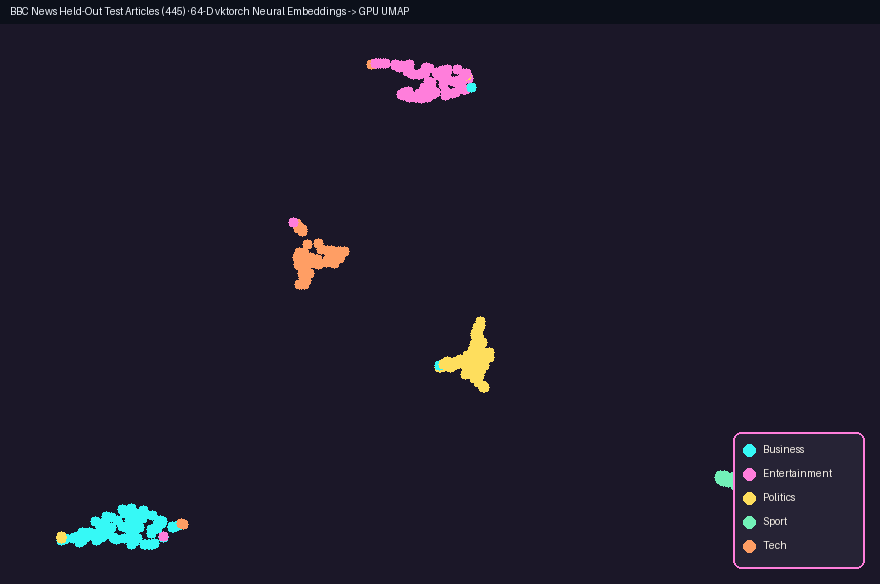

In [4]:
Y_te_umap = vkvis.UMAP(n_neighbors=15, min_dist=0.12, n_epochs=250, metric="cosine", seed=42).fit_transform(E_te)
display(vkvis.render_embedding(
    Y_te_umap, labels=y_te, palette=PALETTE, class_names=CLASS_NAMES, legend_loc="lower right",
    clip_percentile=1.5, background="#1b1728", width=880, height=560, point_size=5,
    title="BBC News Held-Out Test Articles (445) · 64-D vktorch Neural Embeddings -> GPU UMAP",
))


---
### Step 4 · Production **Hybrid Search**: Fusing `BM25` Keywords + 64-D Neural Embeddings (`vkvec.HybridIndex`)

Neural embeddings shattered the Synonym Wall — **so should we throw away keyword search completely?**

**No!** In real-world production AI & `RAG` systems (Elasticsearch, Qdrant, Weaviate), neural embeddings have one blind spot: **rare exact names, product models, or codes** (like `"PlayStation"`, `"FTSE"`, or `"Tony Blair"`). Meanwhile, classic **Okapi `BM25`** (an inverted full-text index) nails exact words with 100% precision.

The production solution is **Hybrid Search** with **Reciprocal Rank Fusion (`RRF`)**:
1. Run **GPU Vector Search** (`vkvec.VectorIndex`) to capture meaning & synonyms.
2. Run **BM25 Full-Text Search** (`vkvec.BM25Index`) to capture exact names, codes & tickers.
3. Fuse both ranked lists with **`RRF`**: `score(d) = sum(w / (60 + rank))` — scale-invariant, zero fragile score tuning!

Let's build a `vkvec.HybridIndex` over all 1,780 full-length BBC News articles, compare all three search modes side-by-side, and verify `.save()` / `.load()` persistence!

In [5]:
DATA_DIR = Path("data/bbc_news"); DATA_DIR.mkdir(parents=True, exist_ok=True)
# Build HybridIndex (Vulkan GPU 64-D Neural Vectors + Okapi BM25 Inverted Index)
t0 = time.perf_counter()
hybrid = vkvec.HybridIndex(metric="cosine").add(
    E_tr,
    texts_tr,
    metadata=[{"topic": CLASS_NAMES[y], "words": len(t.split()), "text": t} for y, t in zip([int(v) for v in y_tr.tolist()], texts_tr)],
)
dt_hyb = time.perf_counter() - t0
print(f"Indexed {len(hybrid):,} full BBC articles into vkvec.HybridIndex ({hybrid.dim}-D GPU + {hybrid.bm25_index.vocab_size:,} BM25 terms) in {dt_hyb:.2f}s\n")

queries = [
    ("Sony PlayStation handheld gaming console", None),
    ("airline fuel oil profit growth", {"topic": "Business"}),
]

for q_text, where_filter in queries:
    q_vec = encode_texts([q_text])
    vec_hits = hybrid.search_vector(q_vec, k=3, where=where_filter)[0]
    bm_hits  = hybrid.search_bm25(q_text, k=3, where=where_filter)[0]
    hyb_hits = hybrid.search(q_vec, q_text, k=3, where=where_filter, mode="rrf", alpha=0.5)[0]

    filt_lbl = f"  [where={where_filter}]" if where_filter else ""
    print(f"=== Query: {q_text!r}{filt_lbl} ===")
    for mode_name, hits in [
        ("Neural Vector Only", vec_hits),
        ("BM25 Keyword Only ", bm_hits),
        ("Hybrid RRF (50/50)", hyb_hits),
    ]:
        top = hits[0]
        snippet = top["metadata"]["text"][:92].replace("\n", " ")
        print(f"  {mode_name} -> [{top['metadata']['topic']:13s}] (score={top['score']:.4f}) {snippet}...")
    print()

# Persist & reload both the vktorch model (.npz) and the vkvec HybridIndex!
model_path = DATA_DIR / "bbc_neural_encoder.npz"
index_path = DATA_DIR / "bbc_hybrid_index.npz"
vt.save(model.state_dict(), model_path)
hybrid.save(index_path)

reloaded = vkvec.HybridIndex.load(index_path)
check = reloaded.search(encode_texts(["Sony PlayStation handheld gaming console"]), "Sony PlayStation handheld gaming console", k=1)[0][0]
print(f"Saved & reloaded vktorch checkpoint ({model_path.stat().st_size/1024:.0f} KB) + vkvec HybridIndex ({len(reloaded):,} docs) -> top hit [{check['metadata']['topic']}] OK!")


Indexed 1,780 full BBC articles into vkvec.HybridIndex (64-D GPU + 26,775 BM25 terms) in 0.48s

=== Query: 'Sony PlayStation handheld gaming console' ===
  Neural Vector Only -> [Tech         ] (score=0.9906) big war games battle it out the arrival of new titles in the popular medal of honor and call...
  BM25 Keyword Only  -> [Tech         ] (score=34.5832) sony psp console hits us in march us gamers will be able to buy sony s playstation portable ...
  Hybrid RRF (50/50) -> [Tech         ] (score=0.0082) big war games battle it out the arrival of new titles in the popular medal of honor and call...

=== Query: 'airline fuel oil profit growth'  [where={'topic': 'Business'}] ===
  Neural Vector Only -> [Business     ] (score=0.9997) euronext  poised to make lse bid  pan-european group euronext is poised to launch a bid for ...
  BM25 Keyword Only  -> [Business     ] (score=16.0897) huge rush for jet airways shares indian airline jet airways  initial public offering was ove...
  Hybrid 

Saved & reloaded vktorch checkpoint (1538 KB) + vkvec HybridIndex (1,780 docs) -> top hit [Tech] OK!


---
### What Did We Learn Across All 3 Data Types (Chapters 1–6)?

| Data Type | Chapters | Dataset | Best Classical ML | Deep Learning (`vktorch`) | Key Takeaway |
|---|---|---|---|---|---|
| **Tabular** | Ch. 1–2 | California Housing (20,640 districts) | `$52.7k` RMSE (`vklearn` KNN) | **`$48.2k` RMSE** (Residual MLP) | Feature engineering + Residual MLPs beat trees/KNN |
| **Image** | Ch. 3–4 | Fashion-MNIST (`28×28` pixels) | `86.45%` (`PCA` + Sobel/HOG) | **`87.70%`** (2D `Conv2d` CNN, `24.5s`) | Learned 3×3 filters beat hand-crafted edges |
| **Vector / Text (`NLP`)** | Ch. 5–6 | Full-Length BBC News (2,225 articles) | `97.30%` (2,000-D `TF-IDF` + Ridge) | **`97.53%`** (64-D Neural Emb + `HybridIndex`) | `31×` smaller vectors + **Synonym Wall broken** + `BM25` Hybrid `RRF` |